<a href="https://colab.research.google.com/github/Ghule-vaibhavi/-machine-learning-model/blob/main/polynomial_regression.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

polynomial regression, Predicting Car Braking Distance

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

data = {
    "Speed": [10, 20, 30, 40, 50, 60, 70, 80],
    "Braking_Distance": [2, 6, 13, 23, 36, 52, 72, 95]
}

df = pd.DataFrame(data)

X = df[["Speed"]]
y = df["Braking_Distance"]

print(df)

   Speed  Braking_Distance
0     10                 2
1     20                 6
2     30                13
3     40                23
4     50                36
5     60                52
6     70                72
7     80                95


In [2]:
# Linear Regression
linear_model = LinearRegression()
linear_model.fit(X, y)

# Polynomial Regression with degree 2
poly_model = make_pipeline(
    PolynomialFeatures(degree=2, include_bias=False),
    LinearRegression()
)

poly_model.fit(X, y)

# Predictions
linear_pred = linear_model.predict(X)
poly_pred = poly_model.predict(X)

print("Linear Regression R2:",
      r2_score(y, linear_pred))

print("Polynomial Regression R2:",
      r2_score(y, poly_pred))

print("Polynomial MSE:",
      mean_squared_error(y, poly_pred))

Linear Regression R2: 0.9453508721542497
Polynomial Regression R2: 0.999950217320543
Polynomial MSE: 0.04836309523809519


/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/utils/validation.py:2739: UserWarning: X does not have valid feature names, but PolynomialFeatures was fitted with feature names
  warnings.warn(


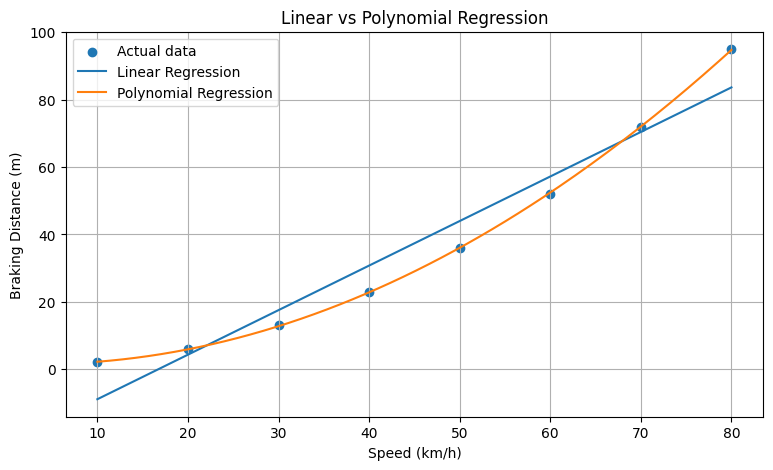

In [3]:
speed_range = np.linspace(
    X["Speed"].min(),
    X["Speed"].max(),
    200
).reshape(-1, 1)

plt.figure(figsize=(9, 5))

plt.scatter(
    X["Speed"], y,
    label="Actual data"
)

plt.plot(
    speed_range.ravel(),
    linear_model.predict(speed_range),
    label="Linear Regression"
)

plt.plot(
    speed_range.ravel(),
    poly_model.predict(speed_range),
    label="Polynomial Regression"
)

plt.xlabel("Speed (km/h)")
plt.ylabel("Braking Distance (m)")
plt.title("Linear vs Polynomial Regression")
plt.legend()
plt.grid(True)
plt.show()

In [4]:
new_speed = pd.DataFrame({"Speed": [45]})

prediction = poly_model.predict(new_speed)

print("Speed:", 45, "km/h")
print("Predicted braking distance:",
      round(prediction[0], 2), "meters")

Speed: 45 km/h
Predicted braking distance: 29.03 meters
